<a href="https://colab.research.google.com/github/Mhamuda/CSEM2151-Computer_Vision/blob/main/Assignment9_Different_Kernels.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Mount google drive

In [ ]:
# ============================================================
# CELL 1: MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully.



#Project paths

In [ ]:
# ============================================================
# CELL 2: PROJECT PATHS
# ============================================================

import os

PROJECT_DIR = "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels"

DATASET_DIR = os.path.join(
    PROJECT_DIR,
    "Dataset_Flowers_Leaves"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "Results"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "Saved_Models"
)

# Result subfolders
DATASET_SPLIT_DIR = os.path.join(
    RESULTS_DIR,
    "Dataset_Split"
)

LEARNING_CURVE_DIR = os.path.join(
    RESULTS_DIR,
    "Learning_Curves"
)

CONFUSION_MATRIX_DIR = os.path.join(
    RESULTS_DIR,
    "Confusion_Matrices"
)

COMPARISON_DIR = os.path.join(
    RESULTS_DIR,
    "Comparison"
)

TEST_PREDICTION_DIR = os.path.join(
    RESULTS_DIR,
    "Test_Predictions"
)

ARCHITECTURE_DIR = os.path.join(
    RESULTS_DIR,
    "Architectures"
)

DATASET_SAMPLE_DIR = os.path.join(
    RESULTS_DIR,
    "Dataset_Samples"
)

MISCLASSIFIED_DIR = os.path.join(
    RESULTS_DIR,
    "Misclassified_Images"
)

# Create directories
all_directories = [
    RESULTS_DIR,
    MODEL_DIR,
    DATASET_SPLIT_DIR,
    LEARNING_CURVE_DIR,
    CONFUSION_MATRIX_DIR,
    COMPARISON_DIR,
    TEST_PREDICTION_DIR,
    ARCHITECTURE_DIR,
    DATASET_SAMPLE_DIR,
    MISCLASSIFIED_DIR
]

for directory in all_directories:
    os.makedirs(directory, exist_ok=True)

print("Project directory:")
print(PROJECT_DIR)

print("\nDataset directory:")
print(DATASET_DIR)

print("\nAll result directories created successfully.")

Project directory:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels

Dataset directory:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Dataset_Flowers_Leaves

All result directories created successfully.


#Check dataset

In [ ]:
# ============================================================
# CELL 3: CHECK DATASET
# ============================================================

import os

flowers_dir = os.path.join(DATASET_DIR, "Flowers")
leaves_dir = os.path.join(DATASET_DIR, "Leaves")

if not os.path.exists(DATASET_DIR):
    raise FileNotFoundError(
        f"Dataset directory not found:\n{DATASET_DIR}"
    )

if not os.path.exists(flowers_dir):
    raise FileNotFoundError(
        f"Flowers folder not found:\n{flowers_dir}"
    )

if not os.path.exists(leaves_dir):
    raise FileNotFoundError(
        f"Leaves folder not found:\n{leaves_dir}"
    )

flower_files = [
    f for f in os.listdir(flowers_dir)
    if os.path.isfile(os.path.join(flowers_dir, f))
]

leaf_files = [
    f for f in os.listdir(leaves_dir)
    if os.path.isfile(os.path.join(leaves_dir, f))
]

print("Flowers images:", len(flower_files))
print("Leaves images:", len(leaf_files))
print("Total images:", len(flower_files) + len(leaf_files))

if len(flower_files) != 150:
    raise ValueError(
        f"Expected 150 flower images, found {len(flower_files)}"
    )

if len(leaf_files) != 150:
    raise ValueError(
        f"Expected 150 leaf images, found {len(leaf_files)}"
    )

print("\nDataset verification successful.")

Flowers images: 150
Leaves images: 150
Total images: 300

Dataset verification successful.


#Import libraries

In [ ]:
# ============================================================
# CELL 4: IMPORT LIBRARIES
# ============================================================

import os
import json
import time
import copy
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    Dataset,
    DataLoader,
    Subset
)

from torchvision import transforms
from torchvision.datasets import ImageFolder

from torchvision.ops import DeformConv2d

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully.")

All libraries imported successfully.


#Reproducibility and device

In [ ]:
# ============================================================
# CELL 5: REPRODUCIBILITY AND DEVICE
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Deterministic behavior
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Random seed:", SEED)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Training will use CPU.")

Random seed: 42
Device: cuda
GPU: Tesla T4


#Common configuration

In [ ]:
# ============================================================
# CELL 6: COMMON CONFIGURATION
# ============================================================

IMG_SIZE = 128

BATCH_SIZE = 16

NUM_WORKERS = 0

NUM_EPOCHS = 20

LEARNING_RATE = 0.001

NUM_CLASSES = 2

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of workers:", NUM_WORKERS)
print("Number of epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Number of classes:", NUM_CLASSES)

Image size: 128
Batch size: 16
Number of workers: 0
Number of epochs: 20
Learning rate: 0.001
Number of classes: 2


#Load base dataset

In [ ]:
# ============================================================
# CELL 7: LOAD BASE DATASET
# ============================================================

base_dataset = ImageFolder(
    root=DATASET_DIR
)

print("Classes:", base_dataset.classes)
print("Class-to-index:", base_dataset.class_to_idx)
print("Total images:", len(base_dataset))

Classes: ['Flowers', 'Leaves']
Class-to-index: {'Flowers': 0, 'Leaves': 1}
Total images: 300


#Verify class distribution

In [ ]:
# ============================================================
# CELL 8: VERIFY CLASS DISTRIBUTION
# ============================================================

class_counts = {}

for class_name, class_index in base_dataset.class_to_idx.items():

    count = sum(
        1 for _, label in base_dataset.samples
        if label == class_index
    )

    class_counts[class_name] = count

print("Class distribution:")

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

if class_counts.get("Flowers", 0) != 150:
    raise ValueError("Flowers class must contain exactly 150 images.")

if class_counts.get("Leaves", 0) != 150:
    raise ValueError("Leaves class must contain exactly 150 images.")

Class distribution:
Flowers: 150
Leaves: 150


#Dataset split

In [ ]:
# ============================================================
# CELL 9: CREATE STRATIFIED TRAIN/VALIDATION/TEST SPLIT
# ============================================================

all_indices = np.arange(len(base_dataset))

all_labels = np.array(
    [label for _, label in base_dataset.samples]
)

# First split:
# 70% training
# 30% temporary
train_indices, temp_indices = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=all_labels
)

# Second split:
# 15% validation
# 15% test
temp_labels = all_labels[temp_indices]

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

train_indices = np.array(train_indices)
val_indices = np.array(val_indices)
test_indices = np.array(test_indices)

print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))
print("Testing images:", len(test_indices))

print(
    "\nTotal:",
    len(train_indices) +
    len(val_indices) +
    len(test_indices)
)

if len(train_indices) != 210:
    raise ValueError("Training split should contain 210 images.")

if len(val_indices) != 45:
    raise ValueError("Validation split should contain 45 images.")

if len(test_indices) != 45:
    raise ValueError("Test split should contain 45 images.")

Training images: 210
Validation images: 45
Testing images: 45

Total: 300


#Save dataset split

In [ ]:
# ============================================================
# CELL 10: SAVE DATASET SPLIT
# ============================================================

split_records = []

for index in train_indices:

    path, label = base_dataset.samples[index]

    split_records.append({
        "index": int(index),
        "path": path,
        "class": base_dataset.classes[label],
        "label": int(label),
        "split": "Train"
    })


for index in val_indices:

    path, label = base_dataset.samples[index]

    split_records.append({
        "index": int(index),
        "path": path,
        "class": base_dataset.classes[label],
        "label": int(label),
        "split": "Validation"
    })


for index in test_indices:

    path, label = base_dataset.samples[index]

    split_records.append({
        "index": int(index),
        "path": path,
        "class": base_dataset.classes[label],
        "label": int(label),
        "split": "Test"
    })


split_df = pd.DataFrame(split_records)

split_csv_path = os.path.join(
    DATASET_SPLIT_DIR,
    "dataset_split.csv"
)

split_df.to_csv(
    split_csv_path,
    index=False
)

print("Dataset split saved to:")
print(split_csv_path)

Dataset split saved to:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Dataset_Split/dataset_split.csv


#Save split distribution

In [ ]:
# ============================================================
# CELL 11: SAVE SPLIT DISTRIBUTION
# ============================================================

distribution_df = (
    split_df
    .groupby(["split", "class"])
    .size()
    .reset_index(name="count")
)

distribution_csv_path = os.path.join(
    DATASET_SPLIT_DIR,
    "dataset_distribution.csv"
)

distribution_df.to_csv(
    distribution_csv_path,
    index=False
)

print(distribution_df)

print(
    "\nSaved to:",
    distribution_csv_path
)

        split    class  count
0        Test  Flowers     23
1        Test   Leaves     22
2       Train  Flowers    105
3       Train   Leaves    105
4  Validation  Flowers     22
5  Validation   Leaves     23

Saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Dataset_Split/dataset_distribution.csv


#Dataset sample visualization

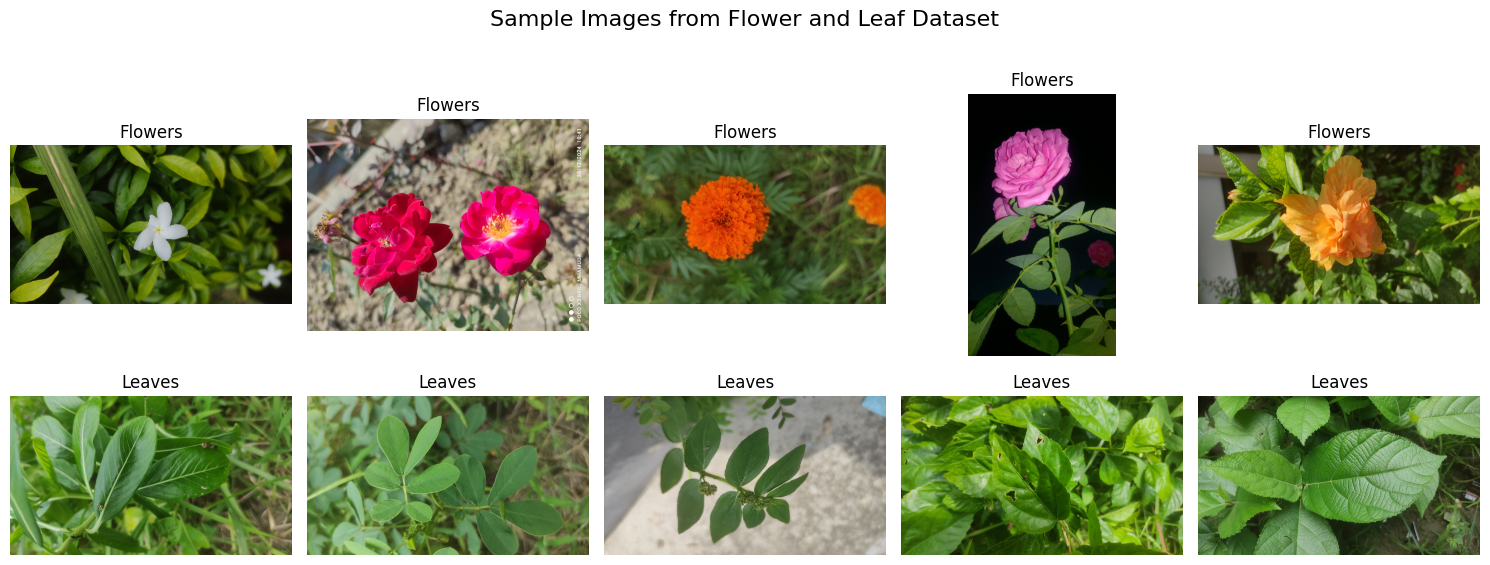

Dataset sample saved:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Dataset_Samples/dataset_samples.png


In [ ]:
# ============================================================
# CELL 12: SAVE DATASET SAMPLE
# ============================================================

sample_indices = []

for class_name in ["Flowers", "Leaves"]:
    class_index = base_dataset.class_to_idx[class_name]
    class_indices = [
        i for i in train_indices
        if base_dataset.samples[i][1] == class_index
    ]
    sample_indices.extend(
        class_indices[:5]
    )

plt.figure(figsize=(15, 6))

# Add the main title over the entire figure
plt.suptitle("Sample Images from Flower and Leaf Dataset", fontsize=16, y=1.02)

for position, index in enumerate(sample_indices):
    image_path, label = base_dataset.samples[index]
    image = Image.open(
        image_path
    ).convert("RGB")

    plt.subplot(2, 5, position + 1)
    plt.imshow(image)
    plt.title(
        base_dataset.classes[label]
    )
    plt.axis("off")

plt.tight_layout()

sample_path = os.path.join(
    DATASET_SAMPLE_DIR,
    "dataset_samples.png"
)

plt.savefig(
    sample_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dataset sample saved:")
print(sample_path)

#Image transforms

In [ ]:
# ============================================================
# CELL 13: IMAGE TRANSFORMS
# ============================================================

train_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])


eval_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])


print("Training and evaluation transforms created.")

Training and evaluation transforms created.


#Create datasets with the SAME split

In [ ]:
# ============================================================
# CELL 14: CREATE TRAIN / VALIDATION / TEST DATASETS
# ============================================================

train_full_dataset = ImageFolder(
    root=DATASET_DIR,
    transform=train_transform
)

eval_full_dataset = ImageFolder(
    root=DATASET_DIR,
    transform=eval_transform
)

train_dataset = Subset(
    train_full_dataset,
    train_indices.tolist()
)

val_dataset = Subset(
    eval_full_dataset,
    val_indices.tolist()
)

test_dataset = Subset(
    eval_full_dataset,
    test_indices.tolist()
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 210
Validation dataset: 45
Test dataset: 45


#Dataloaders

In [ ]:
# ============================================================
# CELL 15: CREATE DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("DataLoaders created successfully.")

print("\nTrain batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully.

Train batches: 14
Validation batches: 3
Test batches: 3


#Verify one batch

In [ ]:
# ============================================================
# CELL 16: VERIFY DATALOADERS
# ============================================================

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels)

if images.shape[0] == 0:
    raise ValueError("Empty training batch.")

print("\nDataLoader verification successful.")

Image batch shape: torch.Size([16, 3, 128, 128])
Label batch shape: torch.Size([16])
Labels: tensor([0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1])

DataLoader verification successful.


#Regular Convolution

In [ ]:
# ============================================================
# CELL 17: REGULAR CONVOLUTION BLOCK
# ============================================================

class RegularConvBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=True
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(
                kernel_size=2,
                stride=2
            )
        )


    def forward(self, x):

        return self.block(x)

#Pointwise 1 X 1 Convolution

In [ ]:
# ============================================================
# CELL 18: POINTWISE 1x1 CONVOLUTION BLOCK
# ============================================================

class PointwiseConvBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                padding=0,
                bias=True
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(
                kernel_size=2,
                stride=2
            )
        )


    def forward(self, x):

        return self.block(x)

#Dilated/Atrous Convolution

In [ ]:
# ============================================================
# CELL 19: DILATED / ATROUS CONVOLUTION BLOCK
# ============================================================

class DilatedConvBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=2,
                dilation=2,
                bias=True
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.MaxPool2d(
                kernel_size=2,
                stride=2
            )
        )


    def forward(self, x):

        return self.block(x)

#Depthwise Separable Convolution

In [ ]:
# ============================================================
# CELL 20: DEPTHWISE SEPARABLE CONVOLUTION BLOCK
# ============================================================

class DepthwiseSeparableBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.depthwise = nn.Conv2d(

            in_channels,

            in_channels,

            kernel_size=3,

            padding=1,

            groups=in_channels,

            bias=True
        )

        self.pointwise = nn.Conv2d(

            in_channels,

            out_channels,

            kernel_size=1,

            padding=0,

            bias=True
        )

        self.batch_norm = nn.BatchNorm2d(
            out_channels
        )

        self.relu = nn.ReLU(
            inplace=True
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )


    def forward(self, x):

        x = self.depthwise(x)

        x = self.pointwise(x)

        x = self.batch_norm(x)

        x = self.relu(x)

        x = self.pool(x)

        return x

#Deformable Convolution

In [ ]:
# ============================================================
# CELL 21: DEFORMABLE CONVOLUTION BLOCK
# ============================================================

class DeformableConvBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        # For a 3x3 kernel:
        # 2 values (x,y) per kernel position
        # 3 x 3 x 2 = 18 offset channels

        self.offset_conv = nn.Conv2d(

            in_channels,

            18,

            kernel_size=3,

            padding=1,

            bias=True
        )

        self.deform_conv = DeformConv2d(

            in_channels,

            out_channels,

            kernel_size=3,

            padding=1,

            bias=True
        )

        self.batch_norm = nn.BatchNorm2d(
            out_channels
        )

        self.relu = nn.ReLU(
            inplace=True
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )


    def forward(self, x):

        offsets = self.offset_conv(x)

        x = self.deform_conv(
            x,
            offsets
        )

        x = self.batch_norm(x)

        x = self.relu(x)

        x = self.pool(x)

        return x

#Common Binary CNN architecture



In [ ]:
# ============================================================
# CELL 22: COMMON BINARY CNN CLASSIFIER
# ============================================================

class BinaryCNN(nn.Module):

    def __init__(
        self,
        block_class
    ):

        super().__init__()

        self.block1 = block_class(
            3,
            32
        )

        self.block2 = block_class(
            32,
            64
        )

        self.block3 = block_class(
            64,
            128
        )

        self.global_pool = nn.AdaptiveAvgPool2d(
            (1, 1)
        )

        self.classifier = nn.Linear(
            128,
            1
        )


    def forward(self, x):

        x = self.block1(x)

        x = self.block2(x)

        x = self.block3(x)

        x = self.global_pool(x)

        x = torch.flatten(
            x,
            start_dim=1
        )

        x = self.classifier(x)

        return x

#Define the Five Models

In [ ]:
# ============================================================
# CELL 23: DEFINE FIVE CNN MODELS
# ============================================================

model_classes = {

    "Regular CNN":
        lambda: BinaryCNN(
            RegularConvBlock
        ),

    "Pointwise CNN":
        lambda: BinaryCNN(
            PointwiseConvBlock
        ),

    "Deformable CNN":
        lambda: BinaryCNN(
            DeformableConvBlock
        ),

    "Dilated CNN":
        lambda: BinaryCNN(
            DilatedConvBlock
        ),

    "Depthwise Separable CNN":
        lambda: BinaryCNN(
            DepthwiseSeparableBlock
        )
}

print("Models defined:")

for model_name in model_classes.keys():
    print("-", model_name)

Models defined:
- Regular CNN
- Pointwise CNN
- Deformable CNN
- Dilated CNN
- Depthwise Separable CNN


#Model Parameter Count

In [ ]:
# ============================================================
# CELL 24: MODEL PARAMETER COUNT
# ============================================================

def count_parameters(model):

    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


parameter_records = []

for model_name, model_function in model_classes.items():

    model = model_function()

    parameters = count_parameters(
        model
    )

    parameter_records.append({

        "Model": model_name,

        "Trainable Parameters": parameters
    })

    print(
        f"{model_name}: "
        f"{parameters:,} parameters"
    )


parameter_df = pd.DataFrame(
    parameter_records
)

parameter_csv = os.path.join(
    COMPARISON_DIR,
    "model_parameters.csv"
)

parameter_df.to_csv(
    parameter_csv,
    index=False
)

print(
    "\nParameter information saved to:"
)

print(parameter_csv)

Regular CNN: 93,825 parameters
Pointwise CNN: 11,137 parameters
Deformable CNN: 109,917 parameters
Dilated CNN: 93,825 parameters
Depthwise Separable CNN: 12,127 parameters

Parameter information saved to:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Comparison/model_parameters.csv


#Save Architecture Information

In [ ]:
# ============================================================
# CELL 25: SAVE MODEL ARCHITECTURES
# ============================================================

for model_name, model_function in model_classes.items():

    model = model_function()

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("/", "_")
    )

    architecture_path = os.path.join(
        ARCHITECTURE_DIR,
        f"{safe_name}.txt"
    )

    with open(
        architecture_path,
        "w"
    ) as file:

        file.write(
            str(model)
        )

        file.write(
            "\n\nTrainable Parameters: "
            + str(count_parameters(model))
        )

    print(
        "Saved:",
        architecture_path
    )

Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Architectures/Regular_CNN.txt
Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Architectures/Pointwise_CNN.txt
Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Architectures/Deformable_CNN.txt
Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Architectures/Dilated_CNN.txt
Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Architectures/Depthwise_Separable_CNN.txt


#Training Function

In [ ]:
# ============================================================
# CELL 26: TRAINING FUNCTION
# ============================================================

def train_model(
    model,
    model_name
):

    model = model.to(DEVICE)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {

        "train_loss": [],
        "val_loss": [],

        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")

    best_val_accuracy = 0.0

    best_state = copy.deepcopy(
        model.state_dict()
    )

    model_folder_name = (
        model_name
        .replace(" ", "_")
        .replace("/", "_")
    )

    model_save_dir = os.path.join(
        MODEL_DIR,
        model_folder_name
    )

    os.makedirs(
        model_save_dir,
        exist_ok=True
    )

    best_model_path = os.path.join(
        model_save_dir,
        "best_model.pth"
    )

    last_model_path = os.path.join(
        model_save_dir,
        "last_model.pth"
    )

    history_csv_path = os.path.join(
        model_save_dir,
        "training_history.csv"
    )

    print(
        f"\nStarting training for {model_name}"
    )

    training_start_time = time.perf_counter()


    for epoch in range(NUM_EPOCHS):

        # ====================================================
        # TRAINING
        # ====================================================

        model.train()

        running_loss = 0.0

        train_correct = 0

        train_total = 0


        for images, labels in train_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.float().to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            outputs = model(
                images
            ).squeeze(1)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()


            batch_size = images.size(0)

            running_loss += (
                loss.item() *
                batch_size
            )


            predictions = (
                torch.sigmoid(outputs) >= 0.5
            ).long()

            train_correct += (
                (predictions == labels.long())
                .sum()
                .item()
            )

            train_total += batch_size


        train_loss = (
            running_loss /
            train_total
        )

        train_accuracy = (
            train_correct /
            train_total
        )


        # ====================================================
        # VALIDATION
        # ====================================================

        model.eval()

        val_running_loss = 0.0

        val_correct = 0

        val_total = 0


        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(
                    DEVICE,
                    non_blocking=True
                )

                labels = labels.float().to(
                    DEVICE,
                    non_blocking=True
                )

                outputs = model(
                    images
                ).squeeze(1)

                loss = criterion(
                    outputs,
                    labels
                )

                batch_size = images.size(0)

                val_running_loss += (
                    loss.item() *
                    batch_size
                )


                predictions = (
                    torch.sigmoid(outputs) >= 0.5
                ).long()

                val_correct += (
                    (predictions == labels.long())
                    .sum()
                    .item()
                )

                val_total += batch_size


        val_loss = (
            val_running_loss /
            val_total
        )

        val_accuracy = (
            val_correct /
            val_total
        )


        # ====================================================
        # SAVE HISTORY
        # ====================================================

        history["train_loss"].append(
            train_loss
        )

        history["val_loss"].append(
            val_loss
        )

        history["train_accuracy"].append(
            train_accuracy
        )

        history["val_accuracy"].append(
            val_accuracy
        )


        # ====================================================
        # SAVE BEST MODEL
        # ====================================================

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_val_accuracy = val_accuracy

            best_state = {
                key: value.detach().cpu().clone()
                for key, value
                in model.state_dict().items()
            }

            torch.save(

                {
                    "model_state_dict":
                        best_state,

                    "model_name":
                        model_name,

                    "epoch":
                        epoch + 1,

                    "val_loss":
                        val_loss,

                    "val_accuracy":
                        val_accuracy,

                    "trainable_parameters":
                        count_parameters(model)
                },

                best_model_path
            )


        # ====================================================
        # SAVE LAST MODEL
        # ====================================================

        torch.save(

            {
                "model_state_dict":
                    model.state_dict(),

                "model_name":
                    model_name,

                "epoch":
                    epoch + 1,

                "train_loss":
                    train_loss,

                "val_loss":
                    val_loss,

                "train_accuracy":
                    train_accuracy,

                "val_accuracy":
                    val_accuracy
            },

            last_model_path
        )


        print(

            f"Epoch "
            f"{epoch + 1:02d}/{NUM_EPOCHS} | "

            f"Train Loss: "
            f"{train_loss:.4f} | "

            f"Val Loss: "
            f"{val_loss:.4f} | "

            f"Train Acc: "
            f"{train_accuracy:.4f} | "

            f"Val Acc: "
            f"{val_accuracy:.4f}"

        )


    training_end_time = time.perf_counter()

    training_time = (
        training_end_time -
        training_start_time
    )


    # Load best model
    model.load_state_dict(
        best_state
    )

    model = model.to(
        DEVICE
    )


    # Save history CSV
    history_df = pd.DataFrame(
        history
    )

    history_df.insert(
        0,
        "Epoch",
        range(
            1,
            len(history_df) + 1
        )
    )

    history_df.to_csv(
        history_csv_path,
        index=False
    )


    # Save history JSON
    history_json_path = os.path.join(
        model_save_dir,
        "training_history.json"
    )

    with open(
        history_json_path,
        "w"
    ) as file:

        json.dump(
            history,
            file,
            indent=4
        )


    print(
        f"\nFinished training: {model_name}"
    )

    print(
        f"Training time: "
        f"{training_time:.2f} seconds"
    )

    print(
        f"Training time: "
        f"{training_time / 60:.2f} minutes"
    )

    print(
        f"Best validation accuracy: "
        f"{best_val_accuracy:.4f}"
    )

    print(
        f"Best model saved at:"
    )

    print(best_model_path)


    return (
        model,
        history,
        training_time,
        best_val_accuracy
    )

#Test training function with one model

In [ ]:
# ============================================================
# CELL 27: QUICK MODEL VERIFICATION
# ============================================================

test_model = model_classes[
    "Regular CNN"
]()

test_model = test_model.to(
    DEVICE
)

test_images, test_labels = next(
    iter(train_loader)
)

test_images = test_images.to(
    DEVICE
)

with torch.no_grad():

    test_output = test_model(
        test_images
    )

print(
    "Input shape:",
    test_images.shape
)

print(
    "Output shape:",
    test_output.shape
)

if test_output.shape != (
    test_images.shape[0],
    1
):

    raise ValueError(
        "Model output shape is incorrect."
    )

print(
    "\nModel verification successful."
)

Input shape: torch.Size([16, 3, 128, 128])
Output shape: torch.Size([16, 1])

Model verification successful.


#Train All Five Models

In [ ]:
# ============================================================
# CELL 28: TRAIN ALL FIVE CNN MODELS
# ============================================================

trained_models = {}

histories = {}

training_times = {}

best_validation_accuracies = {}


for model_name, model_function in model_classes.items():

    print("\n")
    print("=" * 80)
    print("TRAINING:", model_name)
    print("=" * 80)


    model = model_function()


    model, history, training_time, best_val_acc = train_model(

        model,

        model_name
    )


    trained_models[
        model_name
    ] = model


    histories[
        model_name
    ] = history


    training_times[
        model_name
    ] = training_time


    best_validation_accuracies[
        model_name
    ] = best_val_acc


    print(
        f"\nCompleted: {model_name}"
    )

    print(
        f"Training time: "
        f"{training_time:.2f} seconds"
    )

    print(
        f"Training time: "
        f"{training_time / 60:.2f} minutes"
    )

    print(
        f"Best validation accuracy: "
        f"{best_val_acc:.4f}"
    )


print("\n")
print("=" * 80)
print("ALL FIVE MODELS TRAINED SUCCESSFULLY")
print("=" * 80)



TRAINING: Regular CNN

Starting training for Regular CNN
Epoch 01/20 | Train Loss: 0.5784 | Val Loss: 0.5852 | Train Acc: 0.6857 | Val Acc: 0.6667
Epoch 02/20 | Train Loss: 0.4648 | Val Loss: 0.4802 | Train Acc: 0.7667 | Val Acc: 0.7556
Epoch 03/20 | Train Loss: 0.4345 | Val Loss: 0.4245 | Train Acc: 0.8190 | Val Acc: 0.8000
Epoch 04/20 | Train Loss: 0.4334 | Val Loss: 0.3631 | Train Acc: 0.8000 | Val Acc: 0.8889
Epoch 05/20 | Train Loss: 0.3840 | Val Loss: 0.3964 | Train Acc: 0.8333 | Val Acc: 0.8222
Epoch 06/20 | Train Loss: 0.3902 | Val Loss: 0.4163 | Train Acc: 0.8429 | Val Acc: 0.8444
Epoch 07/20 | Train Loss: 0.4089 | Val Loss: 0.3945 | Train Acc: 0.8190 | Val Acc: 0.8000
Epoch 08/20 | Train Loss: 0.4157 | Val Loss: 0.3513 | Train Acc: 0.8143 | Val Acc: 0.8667
Epoch 09/20 | Train Loss: 0.4083 | Val Loss: 0.3973 | Train Acc: 0.8429 | Val Acc: 0.8444
Epoch 10/20 | Train Loss: 0.3523 | Val Loss: 0.3336 | Train Acc: 0.8476 | Val Acc: 0.8889
Epoch 11/20 | Train Loss: 0.3982 | Val Lo

#Save training summary

In [ ]:
# ============================================================
# CELL 29: SAVE TRAINING SUMMARY
# ============================================================

training_summary_records = []

for model_name in model_classes.keys():

    training_summary_records.append({

        "Model":
            model_name,

        "Training Time (seconds)":
            training_times[model_name],

        "Training Time (minutes)":
            training_times[model_name] / 60,

        "Best Validation Accuracy":
            best_validation_accuracies[model_name],

        "Trainable Parameters":
            count_parameters(
                trained_models[model_name]
            )
    })


training_summary_df = pd.DataFrame(
    training_summary_records
)


training_summary_csv = os.path.join(
    COMPARISON_DIR,
    "training_summary.csv"
)


training_summary_df.to_csv(
    training_summary_csv,
    index=False
)


print(
    training_summary_df.to_string(
        index=False
    )
)

print(
    "\nSaved to:",
    training_summary_csv
)

                  Model  Training Time (seconds)  Training Time (minutes)  Best Validation Accuracy  Trainable Parameters
            Regular CNN              1100.373256                18.339554                  0.911111                 93825
          Pointwise CNN               931.035321                15.517255                  0.933333                 11137
         Deformable CNN               923.924681                15.398745                  1.000000                109917
            Dilated CNN               996.750586                16.612510                  0.933333                 93825
Depthwise Separable CNN               983.030000                16.383833                  0.866667                 12127

Saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Comparison/training_summary.csv


#Plot Learning Curves

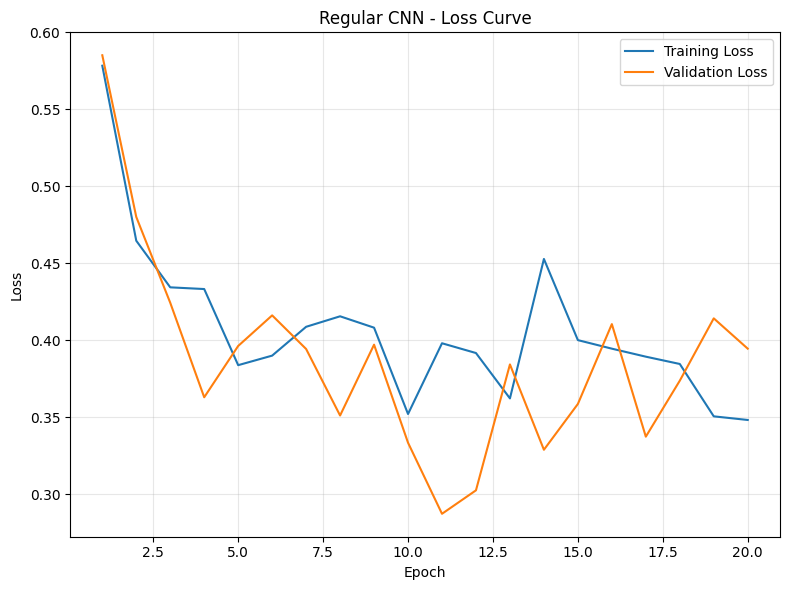

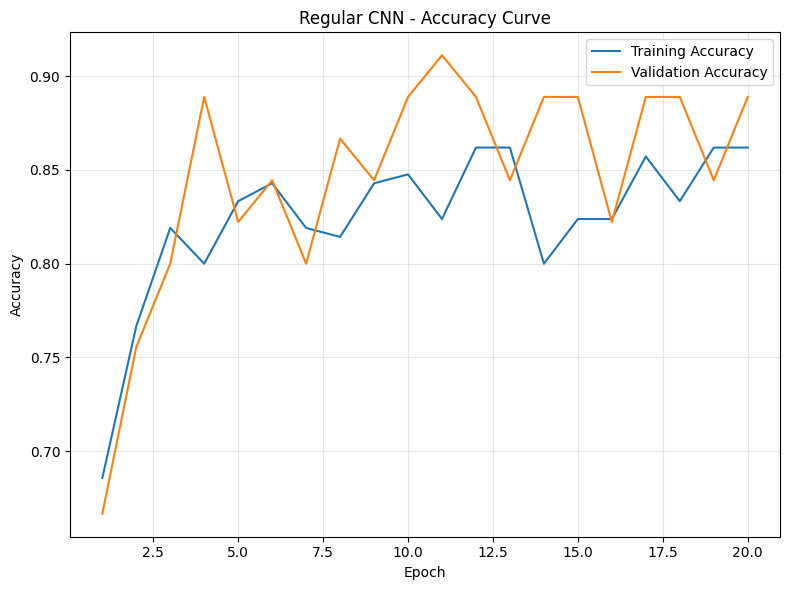

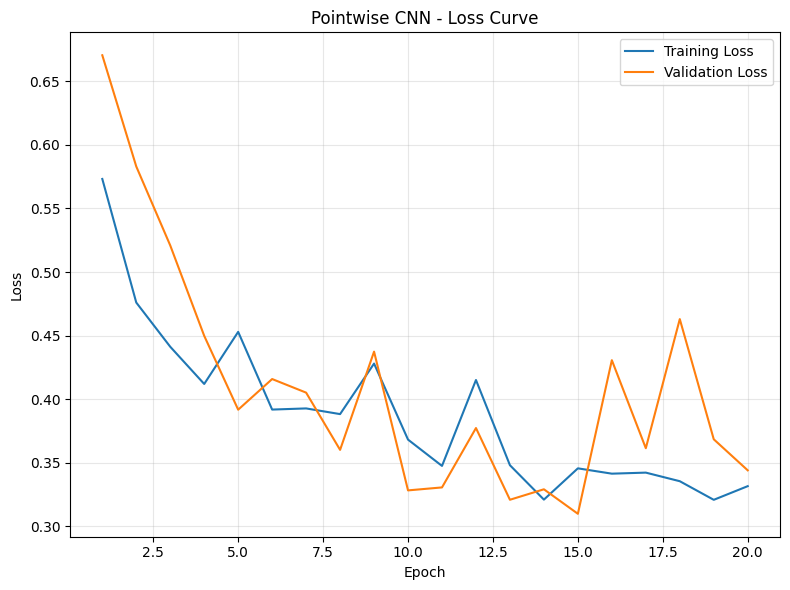

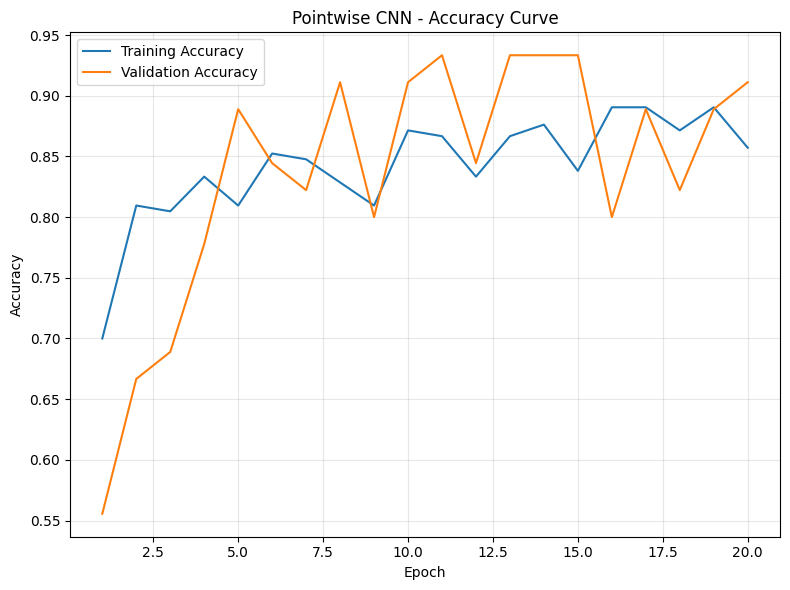

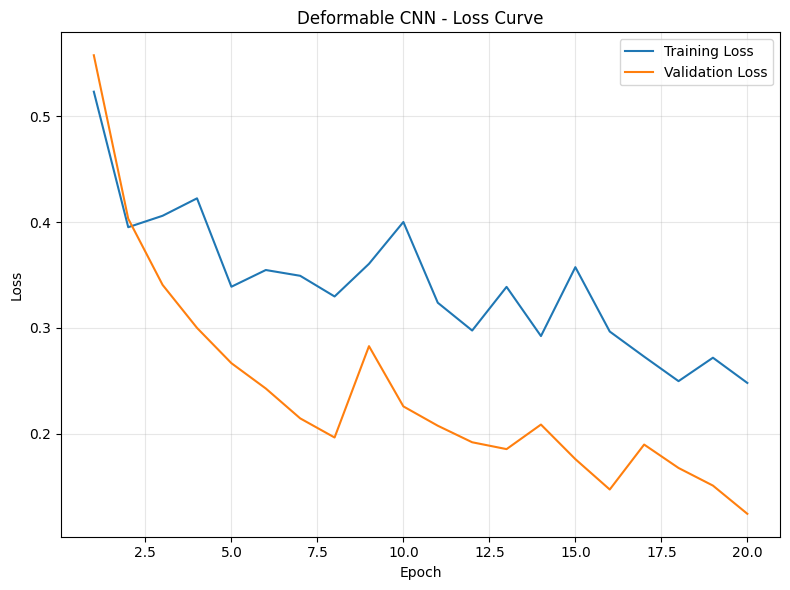

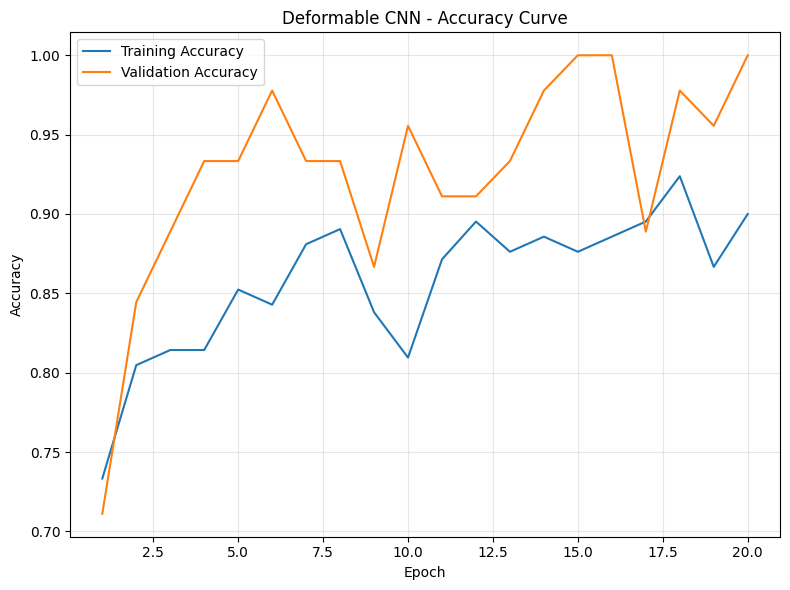

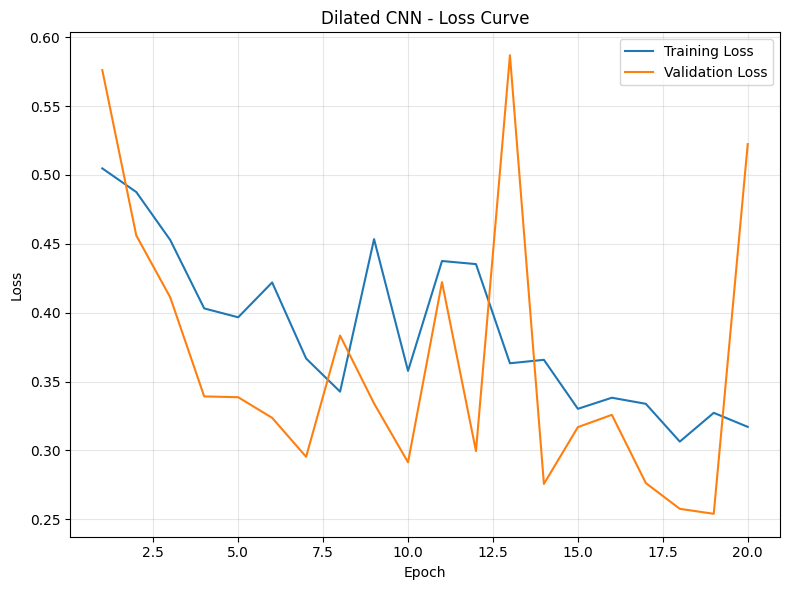

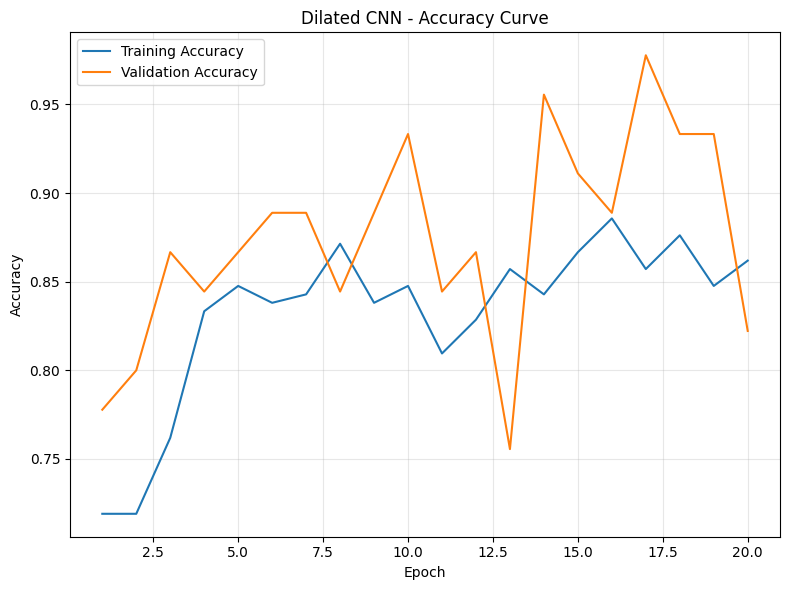

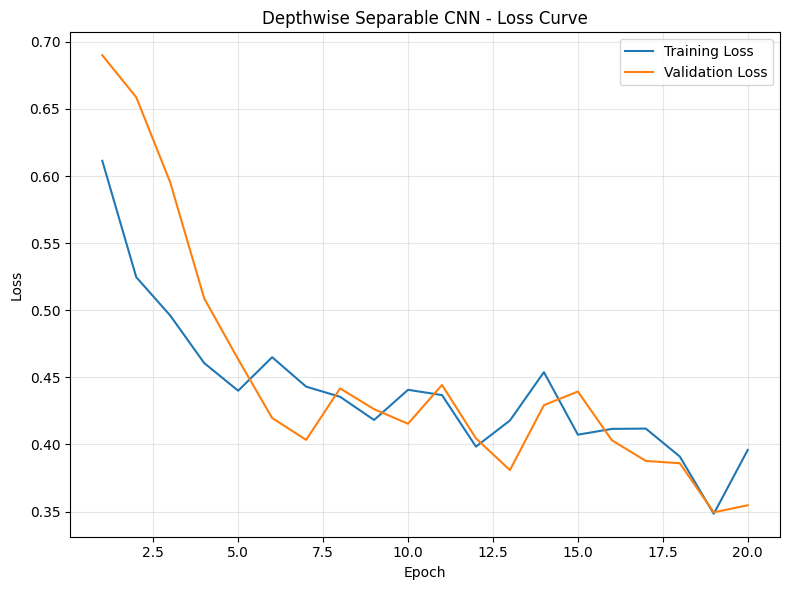

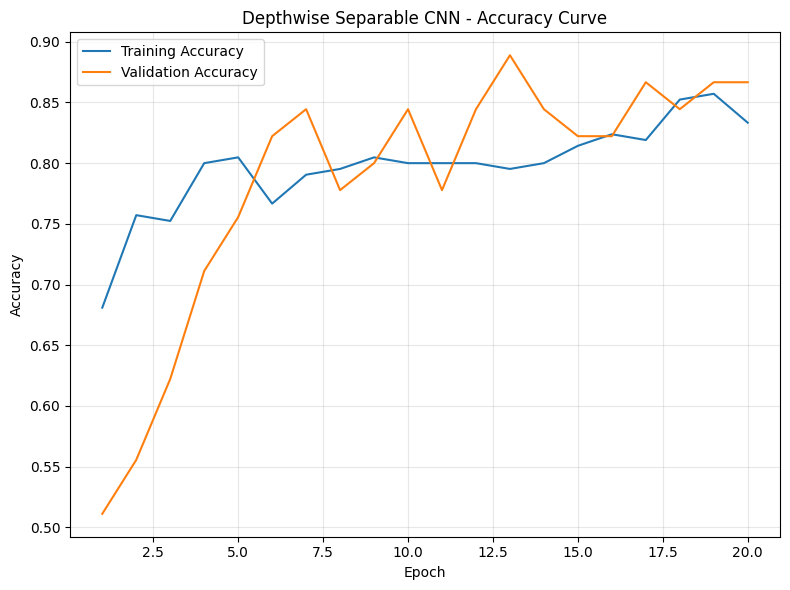

All learning curves saved successfully.


In [ ]:
# ============================================================
# CELL 30: SAVE LEARNING CURVES
# ============================================================

for model_name, history in histories.items():

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("/", "_")
    )


    epochs = range(
        1,
        len(history["train_loss"]) + 1
    )


    # --------------------------------------------------------
    # LOSS CURVE
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 6)
    )

    plt.plot(
        epochs,
        history["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        epochs,
        history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Loss"
    )

    plt.title(
        f"{model_name} - Loss Curve"
    )

    plt.legend()

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()


    loss_path = os.path.join(
        LEARNING_CURVE_DIR,
        f"{safe_name}_loss.png"
    )


    plt.savefig(
        loss_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


    # --------------------------------------------------------
    # ACCURACY CURVE
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 6)
    )

    plt.plot(
        epochs,
        history["train_accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        epochs,
        history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Accuracy"
    )

    plt.title(
        f"{model_name} - Accuracy Curve"
    )

    plt.legend()

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()


    accuracy_path = os.path.join(
        LEARNING_CURVE_DIR,
        f"{safe_name}_accuracy.png"
    )


    plt.savefig(
        accuracy_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


print(
    "All learning curves saved successfully."
)

#Test evaluation Function

In [ ]:
# ============================================================
# CELL 31: TEST EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    model_name
):

    model.eval()

    all_labels = []

    all_predictions = []

    all_probabilities = []

    total_inference_time = 0.0

    total_images = 0


    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )


            # Synchronize GPU before timing
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()


            start_time = time.perf_counter()


            outputs = model(
                images
            ).squeeze(1)


            probabilities = torch.sigmoid(
                outputs
            )


            predictions = (
                probabilities >= 0.5
            ).long()


            if DEVICE.type == "cuda":
                torch.cuda.synchronize()


            end_time = time.perf_counter()


            total_inference_time += (
                end_time -
                start_time
            )


            total_images += images.size(0)


            all_labels.extend(
                labels.cpu().numpy().tolist()
            )

            all_predictions.extend(
                predictions.cpu().numpy().tolist()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )


    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )


    precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )


    recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )


    f1 = f1_score(
        all_labels,
        all_predictions,
        zero_division=0
    )


    cm = confusion_matrix(
        all_labels,
        all_predictions,
        labels=[0, 1]
    )


    avg_inference_time = (
        total_inference_time /
        total_images
    )


    report = classification_report(

        all_labels,

        all_predictions,

        target_names=[
            "Flowers",
            "Leaves"
        ],

        zero_division=0,

        output_dict=True
    )


    return {

        "model_name":
            model_name,

        "accuracy":
            accuracy,

        "precision":
            precision,

        "recall":
            recall,

        "f1":
            f1,

        "confusion_matrix":
            cm,

        "labels":
            all_labels,

        "predictions":
            all_predictions,

        "probabilities":
            all_probabilities,

        "total_inference_time":
            total_inference_time,

        "average_inference_time":
            avg_inference_time,

        "classification_report":
            report
    }

#Evaluate All Five Models

In [ ]:
# ============================================================
# CELL 32: EVALUATE ALL FIVE MODELS
# ============================================================

evaluation_results = {}

for model_name, model in trained_models.items():

    print("\n")
    print("=" * 80)
    print("EVALUATING:", model_name)
    print("=" * 80)


    result = evaluate_model(
        model,
        model_name
    )


    evaluation_results[
        model_name
    ] = result


    print(
        f"Accuracy : "
        f"{result['accuracy']:.4f}"
    )

    print(
        f"Precision: "
        f"{result['precision']:.4f}"
    )

    print(
        f"Recall   : "
        f"{result['recall']:.4f}"
    )

    print(
        f"F1-score : "
        f"{result['f1']:.4f}"
    )

    print(
        f"Total inference time: "
        f"{result['total_inference_time']:.6f} seconds"
    )

    print(
        f"Average inference time/image: "
        f"{result['average_inference_time']:.6f} seconds"
    )


print("\n")
print("=" * 80)
print("ALL MODELS EVALUATED SUCCESSFULLY")
print("=" * 80)



EVALUATING: Regular CNN
Accuracy : 0.9556
Precision: 1.0000
Recall   : 0.9091
F1-score : 0.9524
Total inference time: 0.011260 seconds
Average inference time/image: 0.000250 seconds


EVALUATING: Pointwise CNN
Accuracy : 0.9111
Precision: 0.8750
Recall   : 0.9545
F1-score : 0.9130
Total inference time: 0.008846 seconds
Average inference time/image: 0.000197 seconds


EVALUATING: Deformable CNN
Accuracy : 0.9778
Precision: 1.0000
Recall   : 0.9545
F1-score : 0.9767
Total inference time: 0.026989 seconds
Average inference time/image: 0.000600 seconds


EVALUATING: Dilated CNN
Accuracy : 0.9333
Precision: 0.9524
Recall   : 0.9091
F1-score : 0.9302
Total inference time: 0.013691 seconds
Average inference time/image: 0.000304 seconds


EVALUATING: Depthwise Separable CNN
Accuracy : 0.8889
Precision: 0.8696
Recall   : 0.9091
F1-score : 0.8889
Total inference time: 0.010145 seconds
Average inference time/image: 0.000225 seconds


ALL MODELS EVALUATED SUCCESSFULLY


#Final comparison Table

In [ ]:
# ============================================================
# CELL 33: FINAL MODEL COMPARISON
# ============================================================

comparison_records = []


for model_name in model_classes.keys():

    result = evaluation_results[
        model_name
    ]


    comparison_records.append({

        "Model":
            model_name,

        "Accuracy":
            result["accuracy"],

        "Precision":
            result["precision"],

        "Recall":
            result["recall"],

        "F1-Score":
            result["f1"],

        "Trainable Parameters":
            count_parameters(
                trained_models[model_name]
            ),

        "Training Time (seconds)":
            training_times[model_name],

        "Training Time (minutes)":
            training_times[model_name] / 60,

        "Total Inference Time (seconds)":
            result["total_inference_time"],

        "Average Inference Time (seconds/image)":
            result["average_inference_time"],

        "Best Validation Accuracy":
            best_validation_accuracies[model_name]
    })


comparison_df = pd.DataFrame(
    comparison_records
)


comparison_csv = os.path.join(
    COMPARISON_DIR,
    "final_model_comparison.csv"
)


comparison_df.to_csv(
    comparison_csv,
    index=False
)


print(
    comparison_df.to_string(
        index=False
    )
)


print(
    "\nFinal comparison saved to:"
)

print(comparison_csv)

                  Model  Accuracy  Precision   Recall  F1-Score  Trainable Parameters  Training Time (seconds)  Training Time (minutes)  Total Inference Time (seconds)  Average Inference Time (seconds/image)  Best Validation Accuracy
            Regular CNN  0.955556   1.000000 0.909091  0.952381                 93825              1100.373256                18.339554                        0.011260                                0.000250                  0.911111
          Pointwise CNN  0.911111   0.875000 0.954545  0.913043                 11137               931.035321                15.517255                        0.008846                                0.000197                  0.933333
         Deformable CNN  0.977778   1.000000 0.954545  0.976744                109917               923.924681                15.398745                        0.026989                                0.000600                  1.000000
            Dilated CNN  0.933333   0.952381 0.909091  0.930233 

#Confusion Matrices

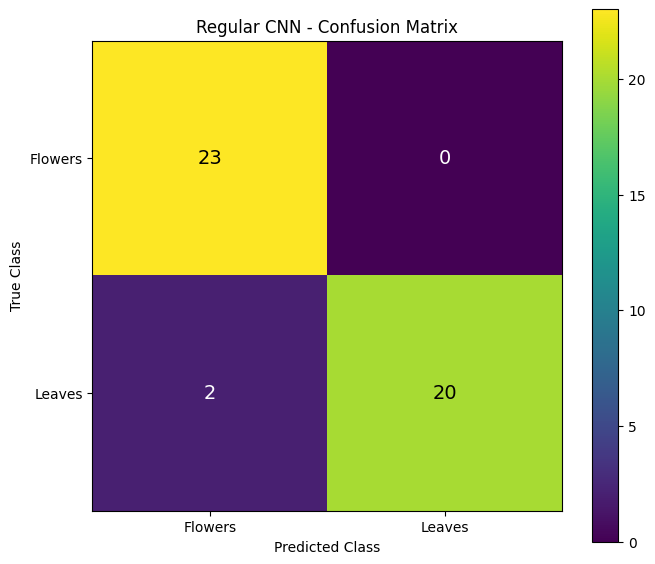

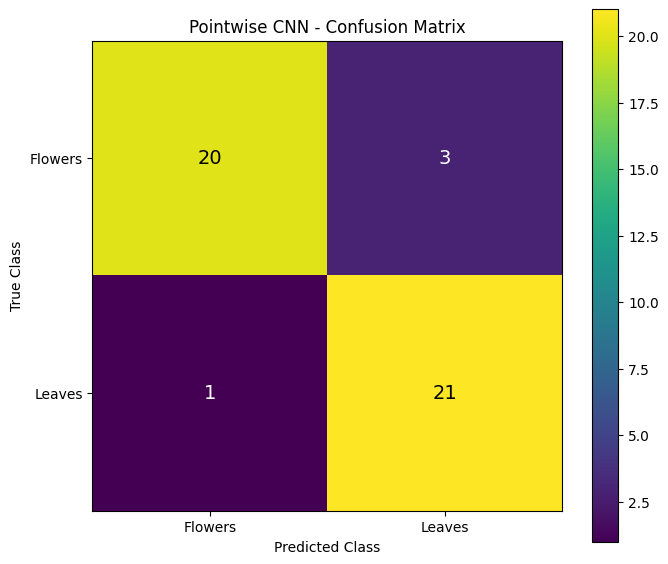

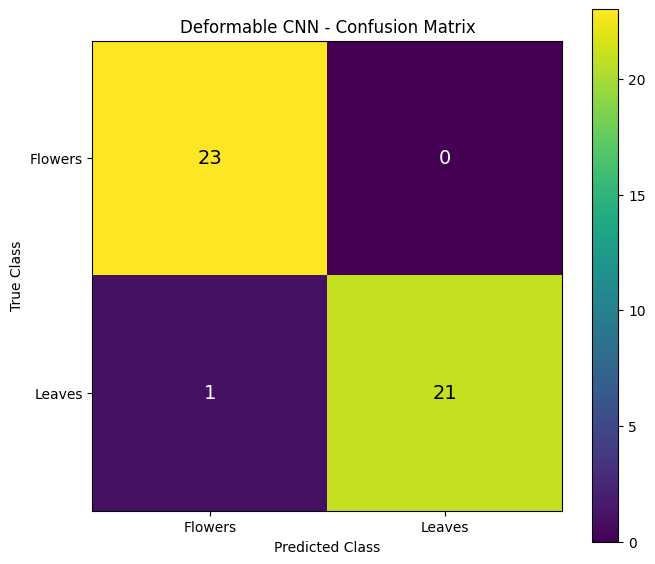

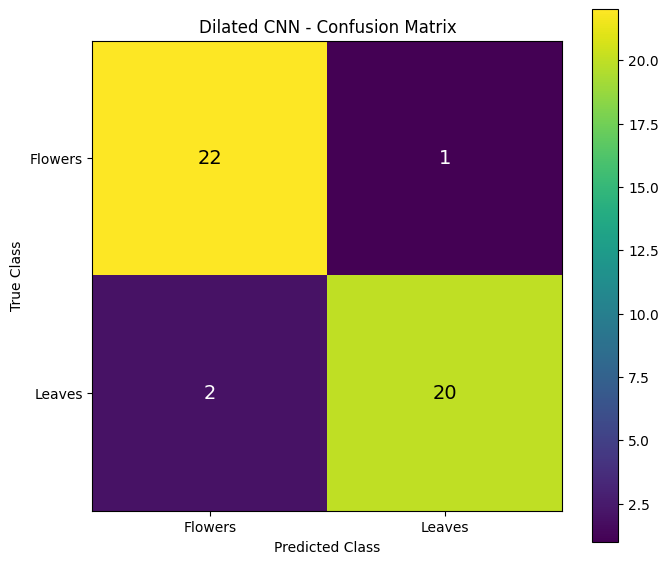

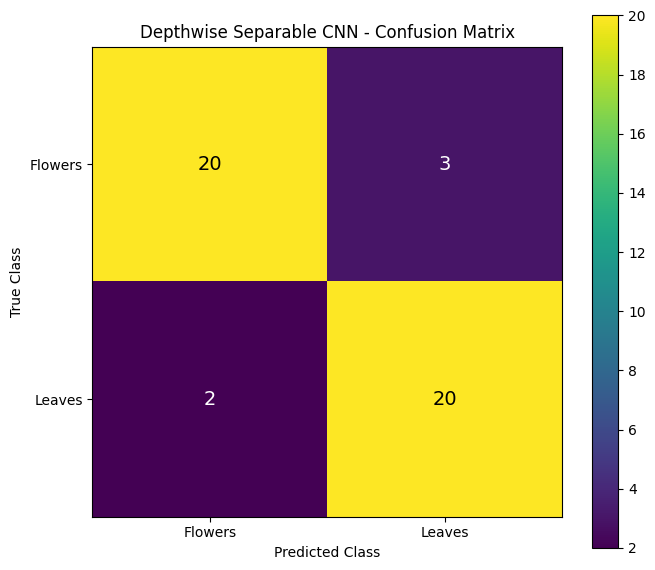

All confusion matrices saved successfully.


In [ ]:
# ============================================================
# CELL 34: CONFUSION MATRICES
# ============================================================

class_names = [
    "Flowers",
    "Leaves"
]


for model_name, result in evaluation_results.items():

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("/", "_")
    )


    cm = result[
        "confusion_matrix"
    ]


    # --------------------------------------------------------
    # SAVE CSV
    # --------------------------------------------------------

    cm_df = pd.DataFrame(

        cm,

        index=class_names,

        columns=class_names
    )


    cm_csv_path = os.path.join(

        CONFUSION_MATRIX_DIR,

        f"{safe_name}_confusion_matrix.csv"
    )


    cm_df.to_csv(
        cm_csv_path
    )


    # --------------------------------------------------------
    # PLOT
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 6)
    )


    plt.imshow(
        cm,
        interpolation="nearest"
    )


    plt.title(
        f"{model_name} - Confusion Matrix"
    )


    plt.colorbar()


    tick_marks = np.arange(
        len(class_names)
    )


    plt.xticks(
        tick_marks,
        class_names
    )


    plt.yticks(
        tick_marks,
        class_names
    )


    threshold = (
        cm.max() / 2
        if cm.max() > 0
        else 0
    )


    for i in range(
        cm.shape[0]
    ):

        for j in range(
            cm.shape[1]
        ):

            plt.text(

                j,

                i,

                str(cm[i, j]),

                ha="center",

                va="center",

                color="black"
                if cm[i, j] > threshold
                else "white",

                fontsize=14
            )


    plt.ylabel(
        "True Class"
    )


    plt.xlabel(
        "Predicted Class"
    )


    plt.tight_layout()


    cm_image_path = os.path.join(

        CONFUSION_MATRIX_DIR,

        f"{safe_name}_confusion_matrix.png"
    )


    plt.savefig(

        cm_image_path,

        dpi=300,

        bbox_inches="tight"
    )


    plt.show()

    plt.close()


print(
    "All confusion matrices saved successfully."
)

#Classification Reports

In [ ]:
# ============================================================
# CELL 35: CLASSIFICATION REPORTS
# ============================================================

for model_name, result in evaluation_results.items():

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("/", "_")
    )


    report_df = pd.DataFrame(
        result["classification_report"]
    ).transpose()


    report_path = os.path.join(

        COMPARISON_DIR,

        f"{safe_name}_classification_report.csv"
    )


    report_df.to_csv(
        report_path
    )


    print(
        f"\n{model_name}"
    )

    print(
        report_df
    )


print(
    "\nClassification reports saved."
)


Regular CNN
              precision    recall  f1-score    support
Flowers        0.920000  1.000000  0.958333  23.000000
Leaves         1.000000  0.909091  0.952381  22.000000
accuracy       0.955556  0.955556  0.955556   0.955556
macro avg      0.960000  0.954545  0.955357  45.000000
weighted avg   0.959111  0.955556  0.955423  45.000000

Pointwise CNN
              precision    recall  f1-score    support
Flowers        0.952381  0.869565  0.909091  23.000000
Leaves         0.875000  0.954545  0.913043  22.000000
accuracy       0.911111  0.911111  0.911111   0.911111
macro avg      0.913690  0.912055  0.911067  45.000000
weighted avg   0.914550  0.911111  0.911023  45.000000

Deformable CNN
              precision    recall  f1-score    support
Flowers        0.958333  1.000000  0.978723  23.000000
Leaves         1.000000  0.954545  0.976744  22.000000
accuracy       0.977778  0.977778  0.977778   0.977778
macro avg      0.979167  0.977273  0.977734  45.000000
weighted avg   0.9787

#Performance comparison chart

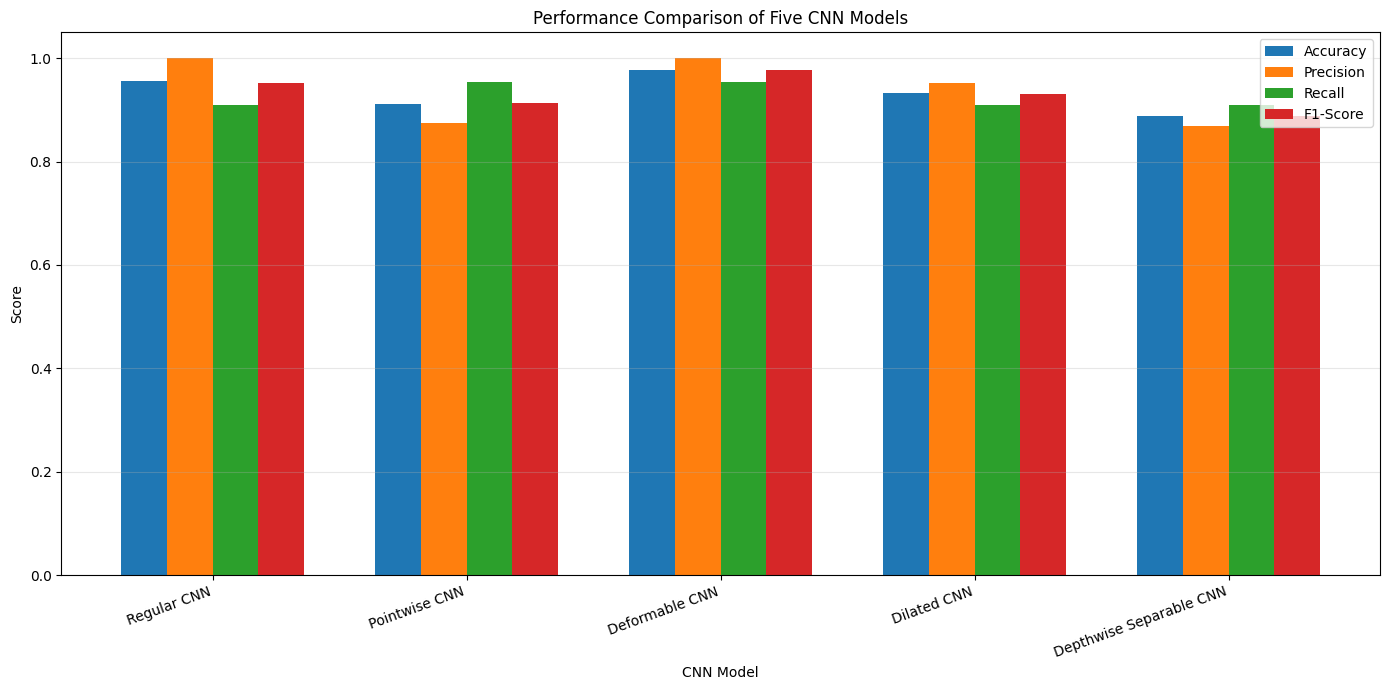

Performance chart saved:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Comparison/performance_comparison.png


In [ ]:
# ============================================================
# CELL 36: PERFORMANCE COMPARISON CHART
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]


x = np.arange(
    len(comparison_df["Model"])
)

width = 0.18


plt.figure(
    figsize=(14, 7)
)


for i, metric in enumerate(metrics):

    plt.bar(

        x + (
            i - 1.5
        ) * width,

        comparison_df[metric],

        width,

        label=metric
    )


plt.xticks(
    x,
    comparison_df["Model"],
    rotation=20,
    ha="right"
)


plt.ylabel(
    "Score"
)


plt.xlabel(
    "CNN Model"
)


plt.title(
    "Performance Comparison of Five CNN Models"
)


plt.ylim(
    0,
    1.05
)


plt.legend()


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


performance_chart_path = os.path.join(

    COMPARISON_DIR,

    "performance_comparison.png"
)


plt.savefig(

    performance_chart_path,

    dpi=300,

    bbox_inches="tight"
)


plt.show()

plt.close()


print(
    "Performance chart saved:"
)

print(performance_chart_path)

#Parameter Comparison

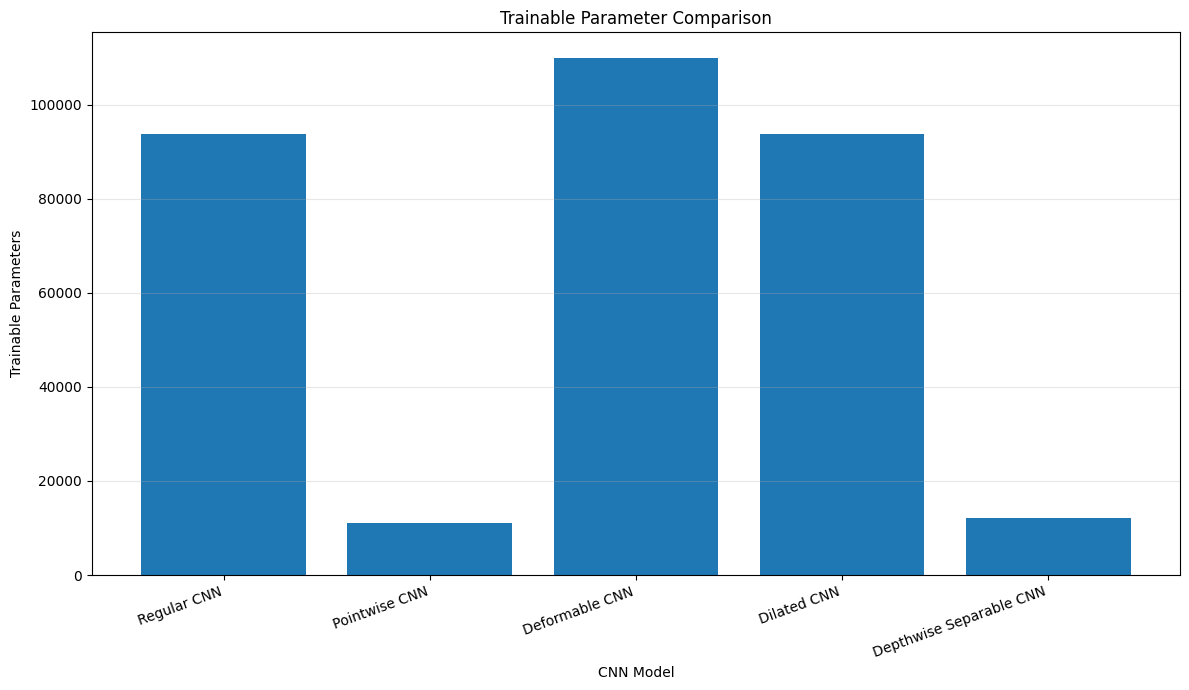

Parameter comparison saved:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Comparison/parameter_comparison.png


In [ ]:
# ============================================================
# CELL 37: PARAMETER COMPARISON
# ============================================================

plt.figure(
    figsize=(12, 7)
)


plt.bar(

    comparison_df["Model"],

    comparison_df["Trainable Parameters"]
)


plt.ylabel(
    "Trainable Parameters"
)


plt.xlabel(
    "CNN Model"
)


plt.title(
    "Trainable Parameter Comparison"
)


plt.xticks(
    rotation=20,
    ha="right"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


parameter_chart_path = os.path.join(

    COMPARISON_DIR,

    "parameter_comparison.png"
)


plt.savefig(

    parameter_chart_path,

    dpi=300,

    bbox_inches="tight"
)


plt.show()

plt.close()


print(
    "Parameter comparison saved:"
)

print(parameter_chart_path)

#Training Time Comparison

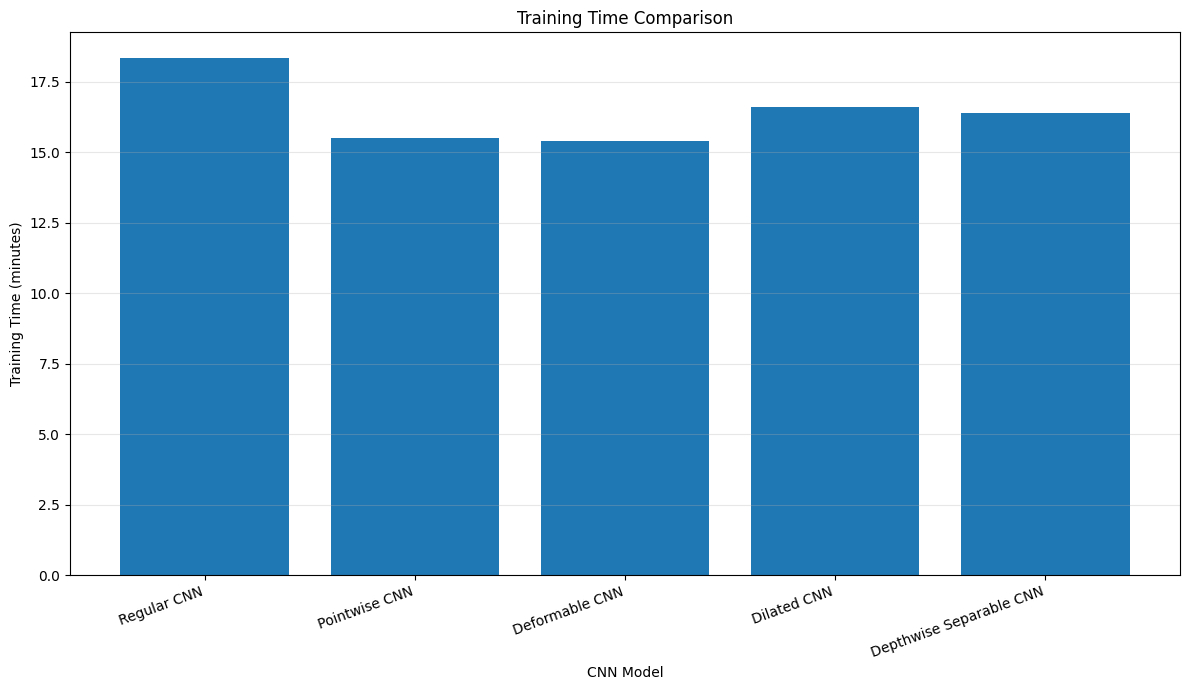

Training time comparison saved:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Comparison/training_time_comparison.png


In [ ]:
# ============================================================
# CELL 38: TRAINING TIME COMPARISON
# ============================================================

plt.figure(
    figsize=(12, 7)
)


plt.bar(

    comparison_df["Model"],

    comparison_df["Training Time (minutes)"]
)


plt.ylabel(
    "Training Time (minutes)"
)


plt.xlabel(
    "CNN Model"
)


plt.title(
    "Training Time Comparison"
)


plt.xticks(
    rotation=20,
    ha="right"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


training_time_chart_path = os.path.join(

    COMPARISON_DIR,

    "training_time_comparison.png"
)


plt.savefig(

    training_time_chart_path,

    dpi=300,

    bbox_inches="tight"
)


plt.show()

plt.close()


print(
    "Training time comparison saved:"
)

print(training_time_chart_path)

#Inference Time Comparison

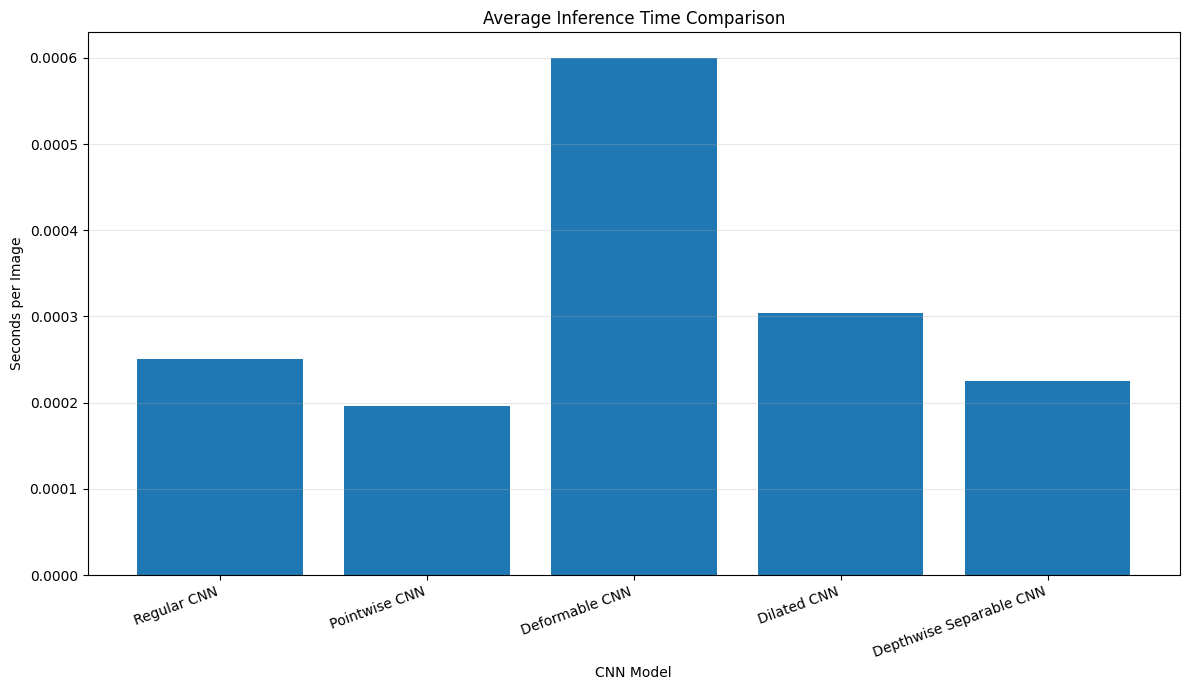

Inference time comparison saved:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Comparison/inference_time_comparison.png


In [ ]:
# ============================================================
# CELL 39: INFERENCE TIME COMPARISON
# ============================================================

plt.figure(
    figsize=(12, 7)
)


plt.bar(

    comparison_df["Model"],

    comparison_df[
        "Average Inference Time (seconds/image)"
    ]
)


plt.ylabel(
    "Seconds per Image"
)


plt.xlabel(
    "CNN Model"
)


plt.title(
    "Average Inference Time Comparison"
)


plt.xticks(
    rotation=20,
    ha="right"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


inference_chart_path = os.path.join(

    COMPARISON_DIR,

    "inference_time_comparison.png"
)


plt.savefig(

    inference_chart_path,

    dpi=300,

    bbox_inches="tight"
)


plt.show()

plt.close()


print(
    "Inference time comparison saved:"
)

print(inference_chart_path)

#Save every test prediction



In [ ]:
# ============================================================
# CELL 40: SAVE TEST PREDICTIONS
# ============================================================

for model_name, result in evaluation_results.items():

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("/", "_")
    )


    prediction_records = []


    for position, original_index in enumerate(
        test_indices
    ):

        image_path, true_label = (
            base_dataset.samples[
                original_index
            ]
        )


        predicted_label = (
            result["predictions"][
                position
            ]
        )


        probability = (
            result["probabilities"][
                position
            ]
        )


        prediction_records.append({

            "Dataset_Index":
                int(original_index),

            "Image_Path":
                image_path,

            "True_Label":
                int(true_label),

            "True_Class":
                class_names[
                    true_label
                ],

            "Predicted_Label":
                int(predicted_label),

            "Predicted_Class":
                class_names[
                    predicted_label
                ],

            "Flower_Probability":
                (
                    1 - probability
                    if predicted_label == 0
                    else probability
                ),

            "Model_Probability_Leaves":
                probability,

            "Correct":
                int(
                    true_label ==
                    predicted_label
                )
        })


    prediction_df = pd.DataFrame(
        prediction_records
    )


    prediction_path = os.path.join(

        TEST_PREDICTION_DIR,

        f"{safe_name}_test_predictions.csv"
    )


    prediction_df.to_csv(

        prediction_path,

        index=False
    )


    print(
        f"Saved: {prediction_path}"
    )


print(
    "\nAll test predictions saved."
)

Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Test_Predictions/Regular_CNN_test_predictions.csv
Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Test_Predictions/Pointwise_CNN_test_predictions.csv
Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Test_Predictions/Deformable_CNN_test_predictions.csv
Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Test_Predictions/Dilated_CNN_test_predictions.csv
Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Test_Predictions/Depthwise_Separable_CNN_test_predictions.csv

All test predictions saved.


#Save misclassified images

In [ ]:
# ============================================================
# CELL 41: SAVE MISCLASSIFIED IMAGES
# ============================================================

for model_name, result in evaluation_results.items():

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("/", "_")
    )


    model_misclassified_dir = os.path.join(

        MISCLASSIFIED_DIR,

        safe_name
    )


    os.makedirs(

        model_misclassified_dir,

        exist_ok=True
    )


    misclassified_count = 0


    for position, original_index in enumerate(
        test_indices
    ):

        image_path, true_label = (
            base_dataset.samples[
                original_index
            ]
        )


        predicted_label = (
            result["predictions"][
                position
            ]
        )


        if true_label != predicted_label:

            original_filename = os.path.basename(
                image_path
            )


            output_filename = (

                f"{position:03d}_"
                f"True_{class_names[true_label]}_"
                f"Pred_{class_names[predicted_label]}_"
                f"{original_filename}"
            )


            output_path = os.path.join(

                model_misclassified_dir,

                output_filename
            )


            shutil.copy2(

                image_path,

                output_path
            )


            misclassified_count += 1


    print(
        f"{model_name}: "
        f"{misclassified_count} misclassified images saved."
    )


print(
    "\nMisclassified image folders created."
)

Regular CNN: 2 misclassified images saved.
Pointwise CNN: 4 misclassified images saved.
Deformable CNN: 1 misclassified images saved.
Dilated CNN: 3 misclassified images saved.
Depthwise Separable CNN: 5 misclassified images saved.

Misclassified image folders created.


#Misclassification summary

In [ ]:
# ============================================================
# CELL 42: MISCLASSIFICATION SUMMARY
# ============================================================

misclassification_records = []


for model_name, result in evaluation_results.items():

    labels = np.array(
        result["labels"]
    )

    predictions = np.array(
        result["predictions"]
    )


    misclassified = np.sum(
        labels != predictions
    )


    misclassification_records.append({

        "Model":
            model_name,

        "Total Test Images":
            len(labels),

        "Correct Predictions":
            np.sum(
                labels == predictions
            ),

        "Misclassified Images":
            misclassified,

        "Test Accuracy":
            result["accuracy"]
    })


misclassification_df = pd.DataFrame(
    misclassification_records
)


misclassification_csv = os.path.join(

    COMPARISON_DIR,

    "misclassification_summary.csv"
)


misclassification_df.to_csv(

    misclassification_csv,

    index=False
)


print(
    misclassification_df.to_string(
        index=False
    )
)


print(
    "\nSaved to:",
    misclassification_csv
)

                  Model  Total Test Images  Correct Predictions  Misclassified Images  Test Accuracy
            Regular CNN                 45                   43                     2       0.955556
          Pointwise CNN                 45                   41                     4       0.911111
         Deformable CNN                 45                   44                     1       0.977778
            Dilated CNN                 45                   42                     3       0.933333
Depthwise Separable CNN                 45                   40                     5       0.888889

Saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Comparison/misclassification_summary.csv


#Test prediction visualization

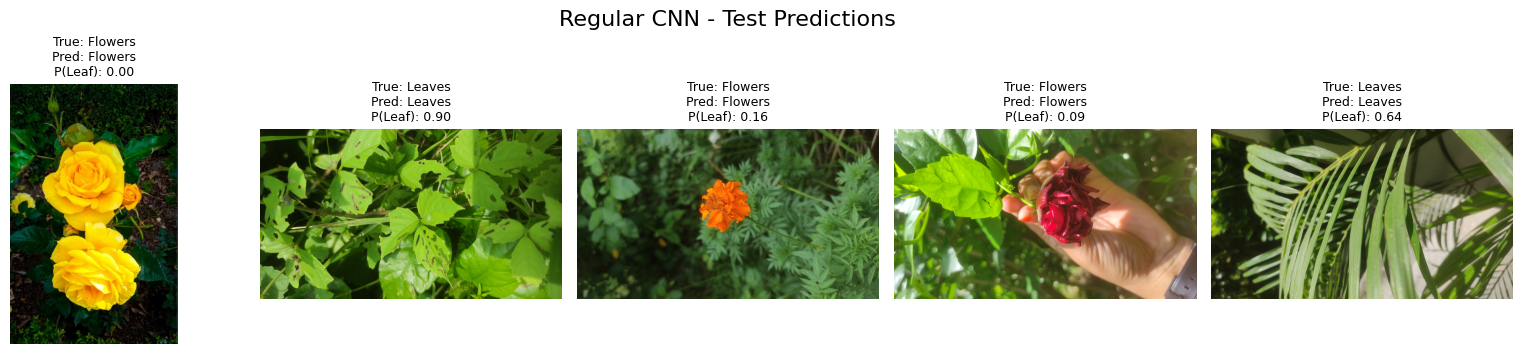

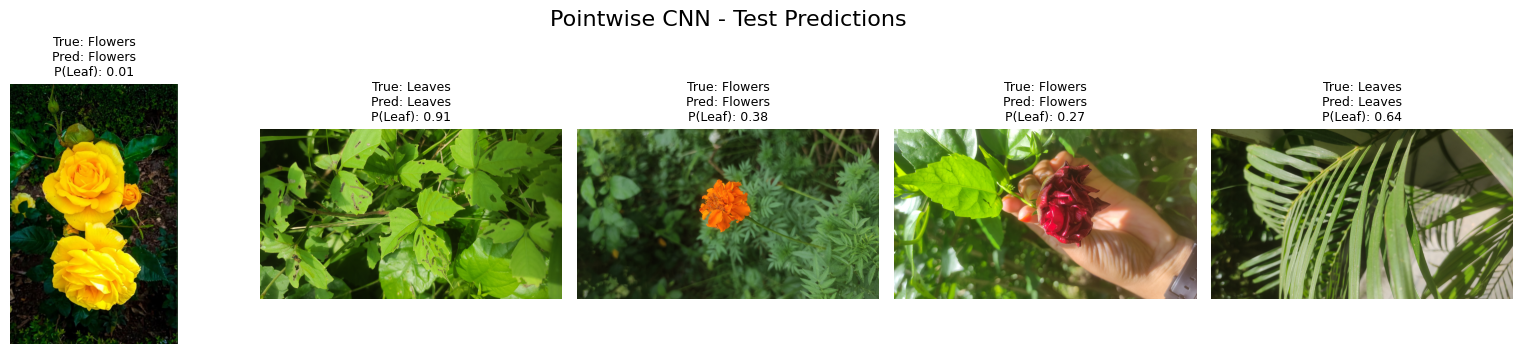

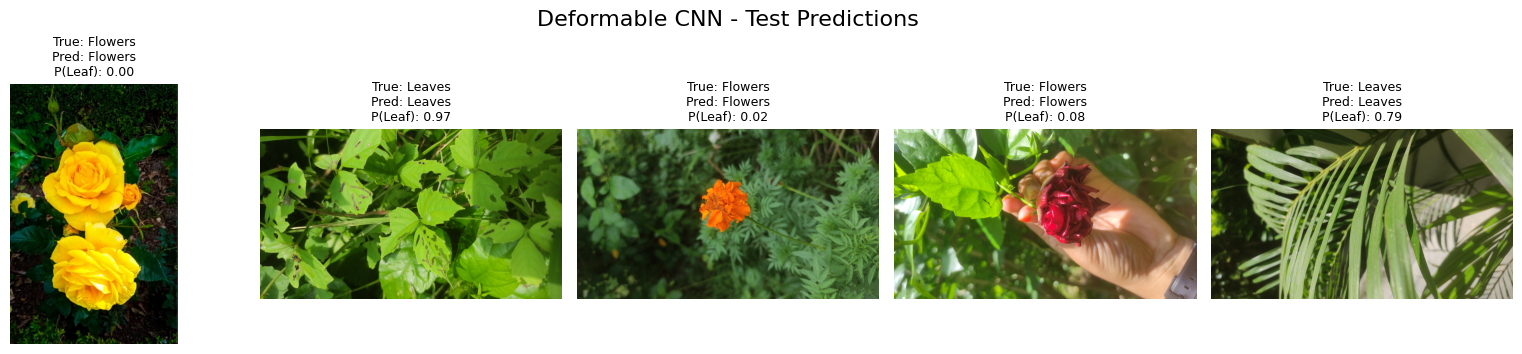

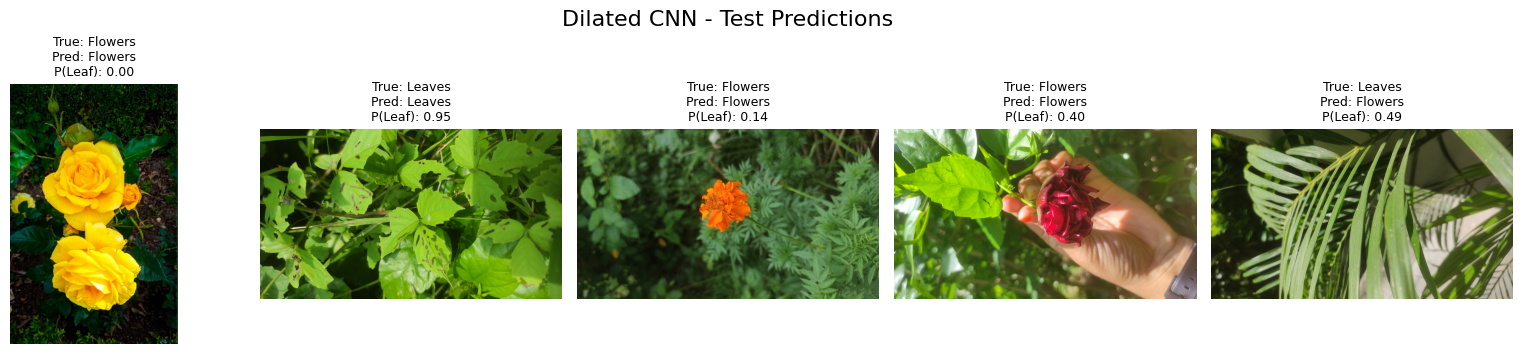

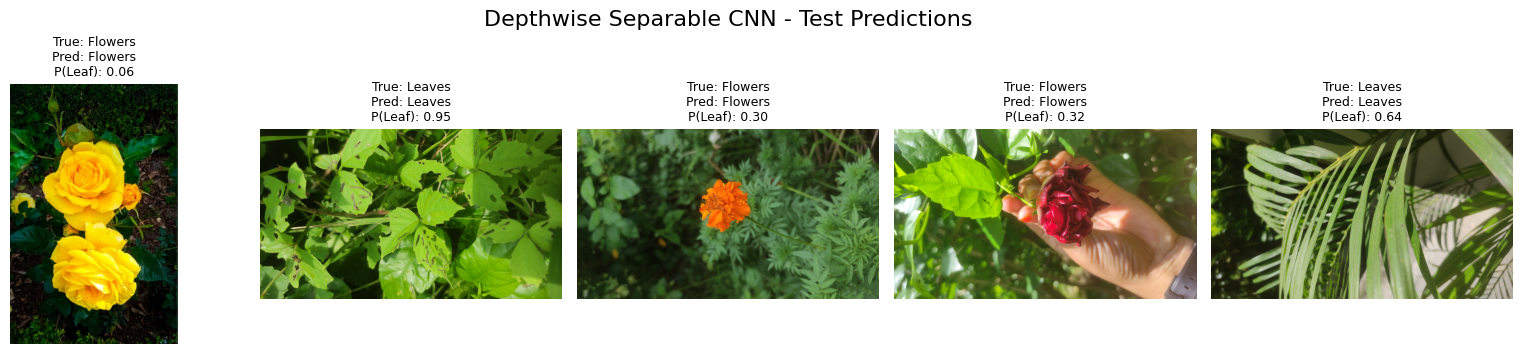

Test prediction visualizations saved.


In [ ]:
# ============================================================
# CELL 43: TEST PREDICTION VISUALIZATION
# ============================================================

for model_name, result in evaluation_results.items():

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("/", "_")
    )


    # Select first 5 test images
    selected_positions = list(
        range(
            min(5, len(test_indices))
        )
    )


    plt.figure(
        figsize=(16, 12)
    )


    for plot_position, position in enumerate(
        selected_positions
    ):

        original_index = (
            test_indices[position]
        )


        image_path, true_label = (
            base_dataset.samples[
                original_index
            ]
        )


        image = Image.open(
            image_path
        ).convert("RGB")


        predicted_label = (
            result["predictions"][
                position
            ]
        )


        probability = (
            result["probabilities"][
                position
            ]
        )


        plt.subplot(
            4,
            5,
            plot_position + 1
        )


        plt.imshow(
            image
        )


        plt.title(

            f"True: {class_names[true_label]}\n"
            f"Pred: {class_names[predicted_label]}\n"
            f"P(Leaf): {probability:.2f}",

            fontsize=9
        )


        plt.axis(
            "off"
        )


    plt.suptitle(
        f"{model_name} - Test Predictions",
        fontsize=16
    )


    plt.tight_layout()


    prediction_image_path = os.path.join(

        TEST_PREDICTION_DIR,

        f"{safe_name}_test_predictions.png"
    )


    plt.savefig(

        prediction_image_path,

        dpi=300,

        bbox_inches="tight"
    )


    plt.show()

    plt.close()


print(
    "Test prediction visualizations saved."
)

#Find best-performing model

In [ ]:
# ============================================================
# CELL 44: BEST PERFORMING MODEL
# ============================================================

best_accuracy_row = comparison_df.loc[
    comparison_df["Accuracy"].idxmax()
]

best_f1_row = comparison_df.loc[
    comparison_df["F1-Score"].idxmax()
]

least_parameter_row = comparison_df.loc[
    comparison_df["Trainable Parameters"].idxmin()
]

fastest_inference_row = comparison_df.loc[
    comparison_df[
        "Average Inference Time (seconds/image)"
    ].idxmin()
]


print("BEST ACCURACY")
print(
    best_accuracy_row[
        ["Model", "Accuracy"]
    ].to_string()
)


print("\nBEST F1-SCORE")
print(
    best_f1_row[
        ["Model", "F1-Score"]
    ].to_string()
)


print("\nFEWEST TRAINABLE PARAMETERS")
print(
    least_parameter_row[
        ["Model", "Trainable Parameters"]
    ].to_string()
)


print("\nFASTEST INFERENCE")
print(
    fastest_inference_row[
        [
            "Model",
            "Average Inference Time (seconds/image)"
        ]
    ].to_string()
)

BEST ACCURACY
Model       Deformable CNN
Accuracy          0.977778

BEST F1-SCORE
Model       Deformable CNN
F1-Score          0.976744

FEWEST TRAINABLE PARAMETERS
Model                   Pointwise CNN
Trainable Parameters            11137

FASTEST INFERENCE
Model                                     Pointwise CNN
Average Inference Time (seconds/image)         0.000197


#Save experiment configuration

In [ ]:
# ============================================================
# CELL 45: SAVE EXPERIMENT CONFIGURATION
# ============================================================

experiment_configuration = {

    "dataset":
        "Flowers and Leaves",

    "dataset_directory":
        DATASET_DIR,

    "flowers_images":
        150,

    "leaves_images":
        150,

    "total_images":
        300,

    "train_images":
        210,

    "validation_images":
        45,

    "test_images":
        45,

    "image_size":
        IMG_SIZE,

    "batch_size":
        BATCH_SIZE,

    "epochs":
        NUM_EPOCHS,

    "learning_rate":
        LEARNING_RATE,

    "optimizer":
        "Adam",

    "loss_function":
        "BCEWithLogitsLoss",

    "random_seed":
        SEED,

    "models": [

        "Regular CNN",

        "Pointwise CNN",

        "Deformable CNN",

        "Dilated CNN",

        "Depthwise Separable CNN"
    ],

    "data_augmentation": [

        "Random Horizontal Flip",

        "Random Rotation (10 degrees)",

        "Color Jitter"
    ],

    "normalization": {

        "mean":
            [0.5, 0.5, 0.5],

        "std":
            [0.5, 0.5, 0.5]
    }
}


configuration_path = os.path.join(

    COMPARISON_DIR,

    "experiment_configuration.json"
)


with open(

    configuration_path,

    "w"
) as file:

    json.dump(

        experiment_configuration,

        file,

        indent=4
    )


print(
    "Experiment configuration saved:"
)

print(configuration_path)

Experiment configuration saved:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment9_Different_Kernels/Results/Comparison/experiment_configuration.json


#Create final report summary

In [ ]:
# ============================================================
# CELL 46: FINAL REPORT SUMMARY
# ============================================================

final_summary = comparison_df.copy()


final_summary["Accuracy (%)"] = (
    final_summary["Accuracy"] * 100
)

final_summary["Precision (%)"] = (
    final_summary["Precision"] * 100
)

final_summary["Recall (%)"] = (
    final_summary["Recall"] * 100
)

final_summary["F1-Score (%)"] = (
    final_summary["F1-Score"] * 100
)


report_columns = [

    "Model",

    "Accuracy (%)",

    "Precision (%)",

    "Recall (%)",

    "F1-Score (%)",

    "Trainable Parameters",

    "Training Time (minutes)",

    "Average Inference Time (seconds/image)"
]


final_report_table = final_summary[
    report_columns
].copy()


final_report_csv = os.path.join(

    COMPARISON_DIR,

    "final_report_summary.csv"
)


final_report_table.to_csv(

    final_report_csv,

    index=False
)


print(
    final_report_table.to_string(
        index=False
    )
)


print(
    "\nFinal report summary saved:"
)

print(final_report_csv)

                  Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Trainable Parameters  Training Time (minutes)  Average Inference Time (seconds/image)
            Regular CNN     95.555556     100.000000   90.909091     95.238095                 93825                18.339554                                0.000250
          Pointwise CNN     91.111111      87.500000   95.454545     91.304348                 11137                15.517255                                0.000197
         Deformable CNN     97.777778     100.000000   95.454545     97.674419                109917                15.398745                                0.000600
            Dilated CNN     93.333333      95.238095   90.909091     93.023256                 93825                16.612510                                0.000304
Depthwise Separable CNN     88.888889      86.956522   90.909091     88.888889                 12127                16.383833                                0.000225

Fin

#Check all important files

In [ ]:
# ============================================================
# CELL 47: CHECK OUTPUT FILES
# ============================================================

print("=" * 80)
print("ASSIGNMENT 9 OUTPUT CHECK")
print("=" * 80)


important_files = [

    split_csv_path,

    distribution_csv_path,

    comparison_csv,

    parameter_csv,

    training_summary_csv,

    final_report_csv,

    performance_chart_path,

    parameter_chart_path,

    training_time_chart_path,

    inference_chart_path
]


for file_path in important_files:

    if os.path.exists(file_path):

        print(
            "✓",
            os.path.basename(file_path)
        )

    else:

        print(
            "✗ MISSING:",
            file_path
        )


print("\nChecking model folders...")


for model_name in model_classes.keys():

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("/", "_")
    )


    model_folder = os.path.join(

        MODEL_DIR,

        safe_name
    )


    best_model = os.path.join(

        model_folder,

        "best_model.pth"
    )


    last_model = os.path.join(

        model_folder,

        "last_model.pth"
    )


    if os.path.exists(
        best_model
    ):

        print(
            "✓ Best model:",
            model_name
        )

    else:

        print(
            "✗ Missing best model:",
            model_name
        )


    if os.path.exists(
        last_model
    ):

        print(
            "✓ Last model:",
            model_name
        )

    else:

        print(
            "✗ Missing last model:",
            model_name
        )


print("\n")
print("=" * 80)
print("ASSIGNMENT 9 PIPELINE COMPLETED")
print("=" * 80)

ASSIGNMENT 9 OUTPUT CHECK
✓ dataset_split.csv
✓ dataset_distribution.csv
✓ final_model_comparison.csv
✓ model_parameters.csv
✓ training_summary.csv
✓ final_report_summary.csv
✓ performance_comparison.png
✓ parameter_comparison.png
✓ training_time_comparison.png
✓ inference_time_comparison.png

Checking model folders...
✓ Best model: Regular CNN
✓ Last model: Regular CNN
✓ Best model: Pointwise CNN
✓ Last model: Pointwise CNN
✓ Best model: Deformable CNN
✓ Last model: Deformable CNN
✓ Best model: Dilated CNN
✓ Last model: Dilated CNN
✓ Best model: Depthwise Separable CNN
✓ Last model: Depthwise Separable CNN


ASSIGNMENT 9 PIPELINE COMPLETED


#Display final result

In [ ]:
# ============================================================
# CELL 48: FINAL RESULT
# ============================================================

display_df = final_report_table.copy()


for column in [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]:

    display_df[column] = (
        display_df[column]
        .round(2)
    )


display_df[
    "Training Time (minutes)"
] = (
    display_df[
        "Training Time (minutes)"
    ].round(2)
)


display_df[
    "Average Inference Time (seconds/image)"
] = (
    display_df[
        "Average Inference Time (seconds/image)"
    ].round(6)
)


print(
    display_df.to_string(
        index=False
    )
)


print("\n")
print("PROJECT DIRECTORY:")
print(PROJECT_DIR)

                  Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Trainable Parameters  Training Time (minutes)  Average Inference Time (seconds/image)
            Regular CNN         95.56         100.00       90.91         95.24                 93825                    18.34                                0.000250
          Pointwise CNN         91.11          87.50       95.45         91.30                 11137                    15.52                                0.000197
         Deformable CNN         97.78         100.00       95.45         97.67                109917                    15.40                                0.000600
            Dilated CNN         93.33          95.24       90.91         93.02                 93825                    16.61                                0.000304
Depthwise Separable CNN         88.89          86.96       90.91         88.89                 12127                    16.38                                0.000225


PR